In [4]:
from google.colab import files
uploaded = files.upload()

Saving fox.jpg to fox.jpg
Saving tennis_ball.jpg to tennis_ball.jpg
Saving bus.jpg to bus.jpg
Saving лошадь.jpg to лошадь.jpg
Saving car.jpg to car.jpg
Saving Айвазовский.jpg to Айвазовский.jpg


In [6]:
import cv2
import matplotlib.pyplot as plt

files = [
    "Айвазовский.jpg",
    "лошадь.jpg",
    "bus.jpg",
    "car.jpg",
    "fox.jpg",
    "tennis_ball.jpg",
]

In [7]:
def process_image(filename):
    # загружажем картинку переводим в ргб
    img_bgr = cv2.imread(filename)
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]  # узнаем размеры изображения

    # полутоновое изображение
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # изменение высоты до 400 пикселей с сохранением пропорций
    new_h = 400
    new_w = int(w * (new_h / h))  # вычисляем новую ширину пропорционально высоте

    # автоматический выбор интерполяции
    if h > new_h:
        interp = cv2.INTER_AREA
        interp_name = "INTER_AREA" # уменьшение
    else:
        interp = cv2.INTER_CUBIC
        interp_name = "INTER_CUBIC" # увеличение

    resized = cv2.resize(img, (new_w, new_h), interpolation=interp)
    print(f"{filename} | исходный размер: {w}x{h}, стало: {new_w}x{new_h} | Интерполяция: {interp_name}")

    # повороты на 180 и 90
    rot_180 = cv2.rotate(img, cv2.ROTATE_180)
    rot_90 = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

    # отражение 0 по вертикали, 1 по горизонтали(зеркально)
    flip_v = cv2.flip(img, 0)
    flip_h = cv2.flip(img, 1)

    # отображение на сетке 2x3
    fig, ax = plt.subplots(2, 3, figsize=(12, 7))

    ax[0, 0].imshow(gray, cmap="gray")
    ax[0, 0].set_title("Полутоновое")

    ax[0, 1].imshow(resized)
    ax[0, 1].set_title(f"Высота 400 {interp_name}")

    ax[0, 2].imshow(rot_180)
    ax[0, 2].set_title("Поворот 180")

    ax[1, 0].imshow(rot_90)
    ax[1, 0].set_title("Поворот 90")

    ax[1, 1].imshow(flip_v)
    ax[1, 1].set_title("Вертикальное отражение")

    ax[1, 2].imshow(flip_h)
    ax[1, 2].set_title("Горизонтальное отражение")

    # Убираем оси координат у всех графиков
    # for a in ax.flat:
    #     a.axis("off")

    plt.tight_layout()
    plt.show()

Айвазовский.jpg | исходный размер: 283x178, стало: 635x400 | Интерполяция: INTER_CUBIC


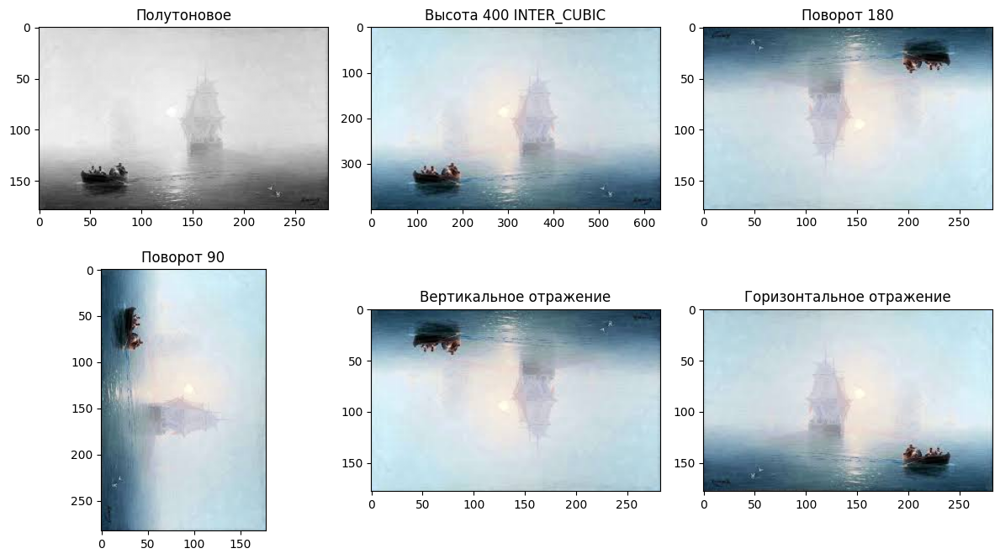

лошадь.jpg | исходный размер: 299x168, стало: 711x400 | Интерполяция: INTER_CUBIC


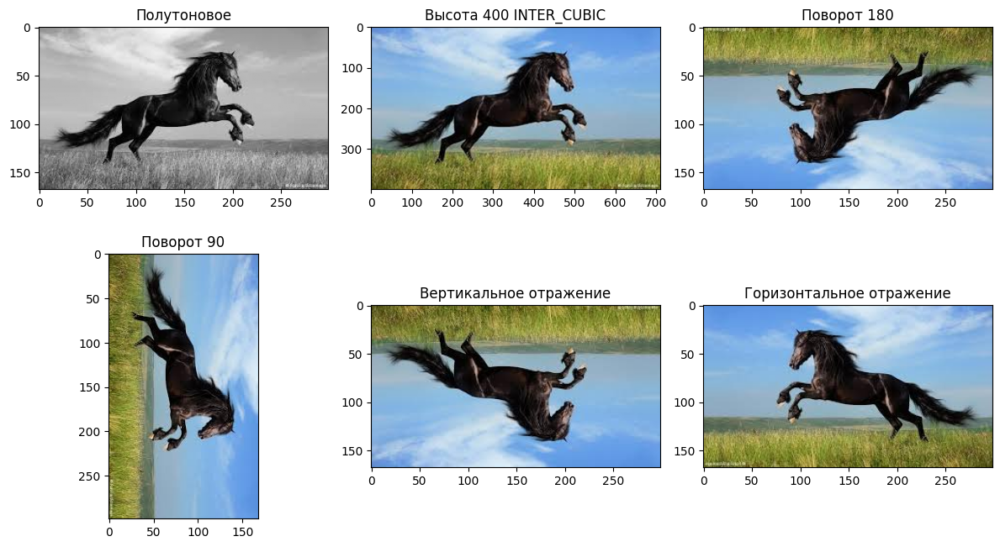

bus.jpg | исходный размер: 1672x941, стало: 710x400 | Интерполяция: INTER_AREA


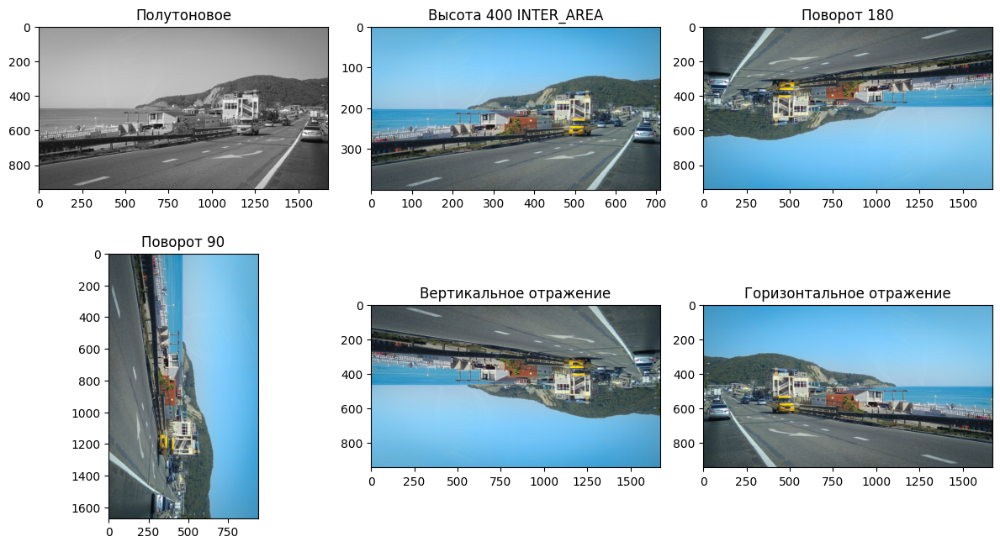

car.jpg | исходный размер: 918x612, стало: 600x400 | Интерполяция: INTER_AREA


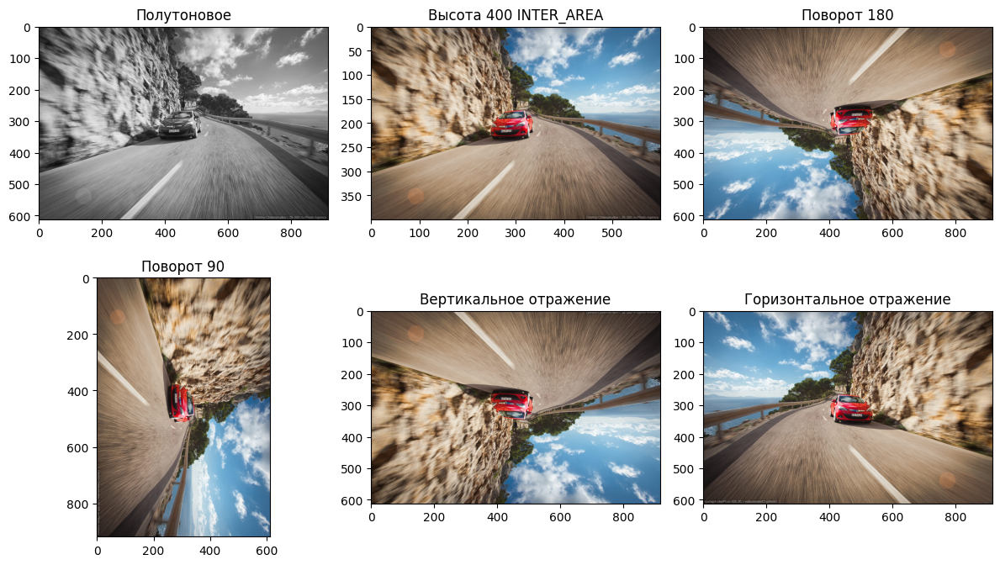

fox.jpg | исходный размер: 259x194, стало: 534x400 | Интерполяция: INTER_CUBIC


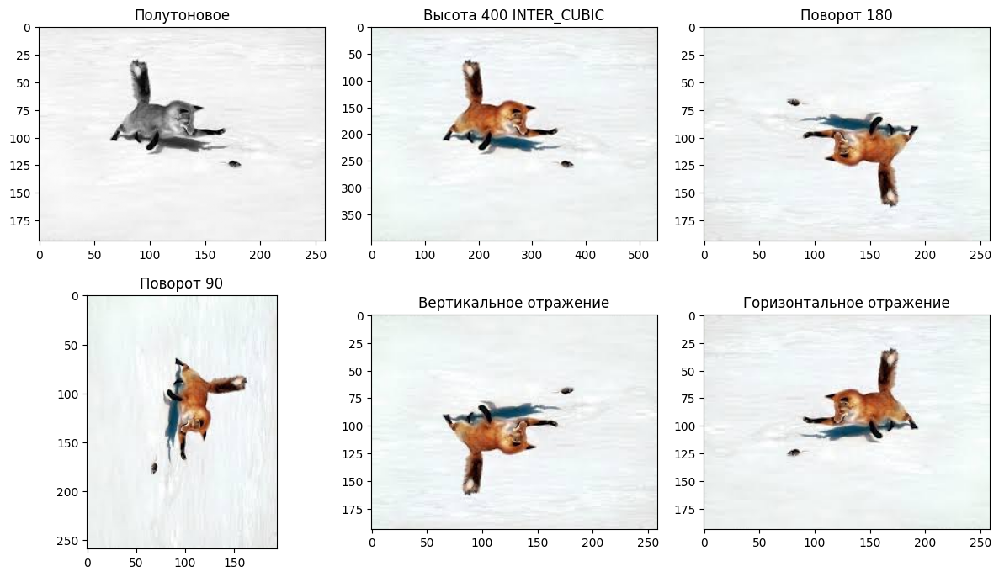

tennis_ball.jpg | исходный размер: 276x183, стало: 603x400 | Интерполяция: INTER_CUBIC


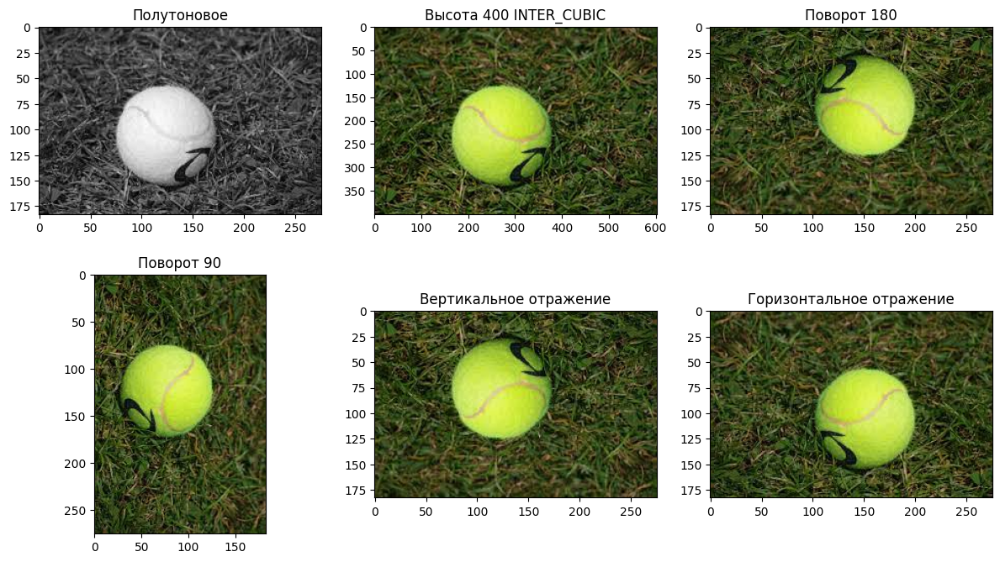

In [8]:
for f in files:
    process_image(f)

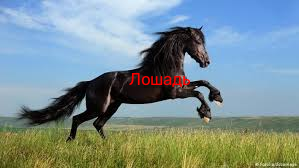

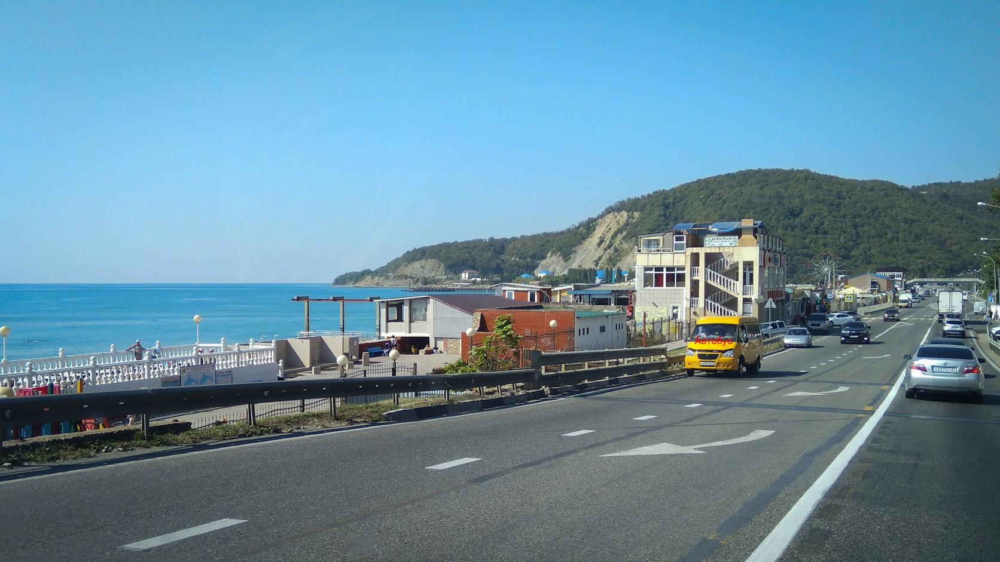

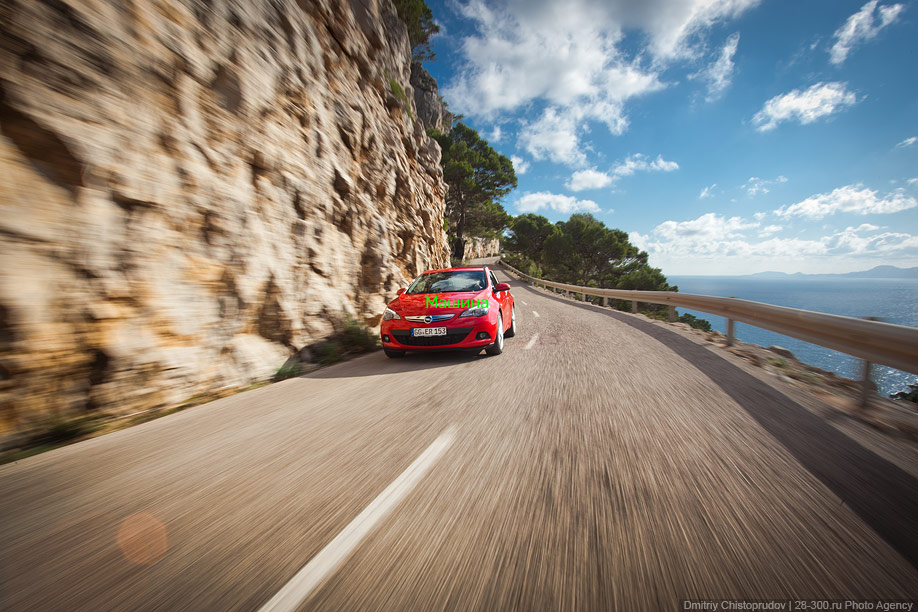

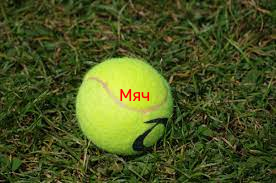

In [34]:
import cv2
from google.colab.patches import cv2_imshow


# находим центр масс по хсв диапозону и оставляем название
def mark_object(img, hsv, low, high, label, text_color=(0, 0, 255), thickness=1):
    mask = cv2.inRange(hsv, low, high)
    moments = cv2.moments(mask, 1)
    area = moments["m00"]
    if area > 0:
        x = int(moments["m10"] / area)
        y = int(moments["m01"] / area)
        cv2.putText(img, label, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, text_color, thickness)

# Черная лошадь, низкая яркость V
img_horse = cv2.imread("лошадь.jpg")
hsv_horse = cv2.cvtColor(img_horse, cv2.COLOR_BGR2HSV)
mark_object(img_horse, hsv_horse, (0, 0, 0), (180, 255, 50), "Лошадь", (0, 0, 255))
cv2_imshow(img_horse)

# Желтый автобус
img_bus = cv2.imread("bus.jpg")
hsv_bus = cv2.cvtColor(img_bus, cv2.COLOR_BGR2HSV)
mark_object(img_bus, hsv_bus, (18, 175, 170), (30, 255, 255), "Автобус", (0, 0, 255))
cv2_imshow(img_bus)

# Красный автомобиль, S > 150
img_car = cv2.imread("car.jpg")
hsv_car = cv2.cvtColor(img_car, cv2.COLOR_BGR2HSV)
mark_object(img_car, hsv_car, (0, 150, 100), (10, 255, 255), "Машина", (0, 255, 0))
cv2_imshow(img_car)

# Салатовый теннисный мяч
img_ball = cv2.imread("tennis_ball.jpg")
hsv_ball = cv2.cvtColor(img_ball, cv2.COLOR_BGR2HSV)
mark_object(img_ball, hsv_ball, (25, 80, 160), (45, 255, 255), "Мяч", (0, 0, 255))
cv2_imshow(img_ball)


In [35]:
def mark_by_contour(img, hsv, low, high, label, text_color=(0, 0, 255), only_right_bottom=False):
    # выделяем объект с помощью hsv фильтра
    mask = cv2.inRange(hsv, low, high)

    # Для поиска мыши оставляем только часть изображения, чтобы не выделять темные лапы лисы
    if only_right_bottom:
        h, w = mask.shape
        mask[:int(h * 0.55), :] = 0  # отступ сверху на 55
        mask[:, :int(w * 0.60)] = 0  # отступ слева на 60


    # ищем все контуры
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        # выбираем самый большой контур в области
        target = max(contours, key=cv2.contourArea)

        # отображаем, ставим имена с помощью поиска центра масс
        cv2.drawContours(img, [target], -1, text_color, 1)

        moments = cv2.moments(target)
        if moments["m00"] > 0:
            x = int(moments["m10"] / moments["m00"])
            y = int(moments["m01"] / moments["m00"])
            cv2.putText(img, label, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, text_color, 1)


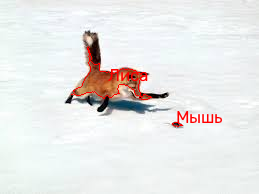

In [36]:
img_fox = cv2.imread("fox.jpg")
hsv_fox = cv2.cvtColor(img_fox, cv2.COLOR_BGR2HSV)

# Лиса самый большой рыжий ноктур
mark_by_contour(img_fox, hsv_fox, (5, 100, 80), (22, 255, 255), "Лиса", (0, 0, 255))

# Мышка самый темный контур в IV четверти
mark_by_contour(img_fox, hsv_fox, (0, 0, 0), (180, 255, 120), "Мышь", (0, 0, 255), only_right_bottom=True)

cv2_imshow(img_fox)


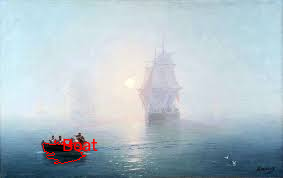

In [32]:
# Лодка, самый большой темный контур
img_boat = cv2.imread("Айвазовский.jpg")
hsv_boat = cv2.cvtColor(img_boat, cv2.COLOR_BGR2HSV)
mark_by_contour(img_boat, hsv_boat, (0, 0, 0), (180, 255, 65), "лодка", (0, 0, 255))
cv2_imshow(img_boat)
